# A pipeline over a group, and a script that reproduces it

The previous notebook ran each step by hand. Here the same analysis is a **pipeline**, BrainO's
built-in `erpcore-p3` spec, run over ten ERP CORE participants. We compare BrainO's scores with
the published ones, look at the group statistics, and export a script that re-runs everything
and checks the results.

About 550 MB of data are downloaded the first time.

In [1]:
import shutil
import warnings
from pathlib import Path

warnings.simplefilter("ignore")  # keep the outputs readable

from braino.datasets import erpcore


def working_copy(task, subjects, folder):
    """Download (or reuse) ERP CORE data and copy it to a folder of its own, so this
    notebook's outputs do not mix with other analyses of the cached data."""
    source = erpcore.fetch(task, subjects)
    target = Path(folder)
    if target.exists():
        shutil.rmtree(target)
    keep = {f"sub-{s}" for s in subjects}
    shutil.copytree(
        source,
        target,
        ignore=lambda folder, names: [
            n for n in names
            if Path(folder) == source and (n == "derivatives" or (n.startswith("sub-") and n not in keep))
        ],
    )
    return target

In [2]:
subjects = [f"{i:03d}" for i in range(1, 11)]
root = working_copy("P3", subjects, "work/erpcore-p3-group")

from braino.pipelines import load_spec

spec = load_spec("erpcore-p3")
for step in [*spec.steps, *spec.group]:
    print(f"{step.id:<14} {step.tool:<28} {list(step.args)}")

preprocess     eeg.preprocess               ['l_freq', 'h_freq', 'resample_hz', 'reference']
ica            eeg.ica_clean                []
bad_channels   eeg.detect_bad_channels      []
epochs         eeg.epoch                    ['tmin', 'tmax', 'baseline', 'event_delay_s', 'conditions']
erp            eeg.erp                      ['contrasts', 'measures']
p3_test        stats.mass_univariate        ['conditions', 'channels', 'tmin', 'tmax', 'correction']
clusters       stats.cluster_permutation    ['conditions', 'tmin', 'tmax']


## Run it

Two steps are decisions (ICA components and bad channels). Run normally, the pipeline stops at
each decision until a person approves it. For this demonstration we pass `auto_approve`, which
approves every proposal as made and records it as auto-approved in every decision.

In [3]:
from collections import Counter

from braino.pipelines import run_pipeline
from braino.tools import RunContext

report = run_pipeline(spec, RunContext(dataset_root=root),
                      auto_approve="user:example (auto-approved in a notebook)")
print(Counter(o.status for o in report.outcomes))

Counter({'ran': 52})


## BrainO's scores and the published ones

ERP CORE excluded participants with more than 25% of trials rejected; the authors also excluded
participants 006, 009 and 010 for this task.

In [4]:
from braino.pipelines import load_state

state = load_state(RunContext(dataset_root=root), spec)
published = erpcore.references()["P3"]
rows = []
for s in subjects:
    erp = state.records[f"{s}/erp"].result
    score = next(m["value_uv"] for m in erp["measures"] if m["waveform"] == "difference")
    rejected = state.records[f"{s}/epochs"].result["rejected_fraction"]
    rows.append((s, score, published.subject_scores_uv.get(s), rejected))
    shown = f"{published.subject_scores_uv[s]:6.2f}" if s in published.subject_scores_uv else "  excl"
    print(f"{s}  BrainO {score:6.2f} µV   published {shown}   rejected {rejected:.0%}")

001  BrainO   6.65 µV   published   6.59   rejected 0%
002  BrainO  17.47 µV   published  17.75   rejected 0%
003  BrainO   9.95 µV   published   9.85   rejected 8%
004  BrainO   6.98 µV   published   7.46   rejected 0%
005  BrainO   4.30 µV   published   4.18   rejected 18%
006  BrainO   1.86 µV   published   excl   rejected 14%
007  BrainO   3.94 µV   published   6.82   rejected 2%
008  BrainO   4.84 µV   published   4.69   rejected 15%
009  BrainO   6.20 µV   published   excl   rejected 31%
010  BrainO   5.23 µV   published   excl   rejected 7%


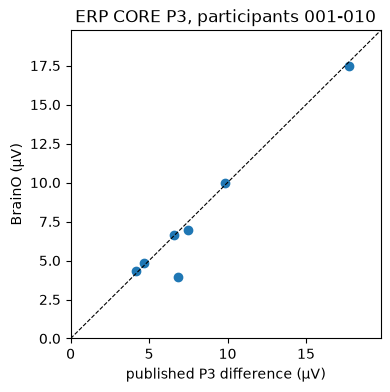

In [5]:
import matplotlib.pyplot as plt

both = [(b, p) for _, b, p, _ in rows if p is not None]
fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter([p for _, p in both], [b for b, _ in both])
lim = [0, max(max(x) for x in both) + 2]
ax.plot(lim, lim, "k--", lw=0.8)
ax.set(xlabel="published P3 difference (µV)", ylabel="BrainO (µV)", xlim=lim, ylim=lim,
       title="ERP CORE P3, participants 001-010");

In [6]:
from braino.validation.erpcore import MAX_REJECTED, compare

kept = {s: b for s, b, _, r in rows if r <= MAX_REJECTED}
excluded = [s for s, _, _, r in rows if r > MAX_REJECTED]
result = compare("P3", kept, excluded=excluded)
print(f"r = {result.correlation} over {result.n_compared} participants; "
      f"mean |difference| {result.mean_abs_difference_uv} µV")
print(result.exclusions)

r = 0.973 over 7 participants; mean |difference| 0.583 µV
both=['009'] only_braino=[] only_published=['006', '010', '030', '035', '040']


With ten participants the group-level checks (confidence interval, p < .001) are not meant to
pass yet; `braino validate erpcore P3` runs all 40 participants.

## Group statistics

The spec's group steps ran over the participants: a t-test of the difference wave at Pz in the
P3 window (FDR-corrected), and a cluster permutation test over all channels and 0-800 ms.

In [7]:
test = state.records["group/p3_test"].result["result"]
print(test["test"], "| peak t", test["peak_stat"], "at", test["peak_at"], "| min p", test["min_p"])
clusters = state.records["group/clusters"].result["result"]
for c in clusters["clusters"][:3]:
    print(f"cluster p = {c['p']:.4f}, {c['sign']}, {c['ranges']['time']} s, "
          f"{len(c['channels'])} channels")

one-sample t-test against 0 | peak t 6.115 at {'time': 0.3242} | min p 0.0028550293804974086
cluster p = 0.0039, positive, [0.2227, 0.668] s, 29 channels
cluster p = 0.4688, positive, [0.1953, 0.2383] s, 10 channels
cluster p = 0.9766, positive, [0.0742, 0.082] s, 3 channels


## Results are reused

Running the pipeline again redoes nothing: every step's tool, arguments and input and output
files are unchanged. Change one step's settings, or pass `from_step`, and only that step and the
ones after it run again.

In [8]:
again = run_pipeline(spec, RunContext(dataset_root=root), auto_approve="user:example")
Counter(o.status for o in again.outcomes)

Counter({'cached': 52})

## A script that reproduces it

`braino pipeline export` (here, its Python form) writes a standalone script. Run on a fresh copy
of the data, it re-runs every step, makes the recorded decisions again, and checks every number
each step reported.

In [9]:
from braino.provenance.export import original_inputs, render_script, steps_from_pipeline

ctx = RunContext(dataset_root=root)
steps, calls, environment = steps_from_pipeline(ctx.derivatives_root, state, spec, ctx.proposals)
script = Path("work/erpcore_p3_group.py")
script.write_text(render_script(steps, title="ERP CORE P3, 10 participants",
                                environment=environment, inputs=original_inputs(calls)),
                  encoding="utf-8")
print(f"{len(steps)} steps")

52 steps


In [10]:
import subprocess
import sys

copy = working_copy("P3", subjects, "work/erpcore-p3-replay")
result = subprocess.run([sys.executable, str(script), str(copy)], capture_output=True, text=True)
print(result.stdout.splitlines()[-1])

reproduced: all 52 steps gave the recorded results
